In [1]:
import pandas as pd
import matplotlib.pyplot as plt

movies = pd.read_csv("data/movies.csv")
ratings = pd.read_csv("data/ratings.csv")

In [2]:
print(movies["genres"].head(10))

0    Adventure|Animation|Children|Comedy|Fantasy
1                     Adventure|Children|Fantasy
2                                 Comedy|Romance
3                           Comedy|Drama|Romance
4                                         Comedy
5                          Action|Crime|Thriller
6                                 Comedy|Romance
7                             Adventure|Children
8                                         Action
9                      Action|Adventure|Thriller
Name: genres, dtype: str


In [3]:
genres_split = movies["genres"].str.split("|")

print(genres_split.head())

0    [Adventure, Animation, Children, Comedy, Fantasy]
1                       [Adventure, Children, Fantasy]
2                                    [Comedy, Romance]
3                             [Comedy, Drama, Romance]
4                                             [Comedy]
Name: genres, dtype: object


In [4]:
genres_exploded = genres_split.explode()

print(genres_exploded.head(15))

0    Adventure
0    Animation
0     Children
0       Comedy
0      Fantasy
1    Adventure
1     Children
1      Fantasy
2       Comedy
2      Romance
3       Comedy
3        Drama
3      Romance
4       Comedy
5       Action
Name: genres, dtype: str


In [5]:
unique_genres = genres_exploded.unique()

print("=== Unique Genres ===")
print(sorted(unique_genres))

print("\nNumber of genres:", len(unique_genres))

=== Unique Genres ===
['(no genres listed)', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']

Number of genres: 20


In [6]:
genre_counts = genres_exploded.value_counts()

print("=== Genre Counts ===")
print(genre_counts)

=== Genre Counts ===
genres
Drama                 4361
Comedy                3756
Thriller              1894
Action                1828
Romance               1596
Adventure             1263
Crime                 1199
Sci-Fi                 980
Horror                 978
Fantasy                779
Children               664
Animation              611
Mystery                573
Documentary            440
War                    382
Musical                334
Western                167
IMAX                   158
Film-Noir               87
(no genres listed)      34
Name: count, dtype: int64


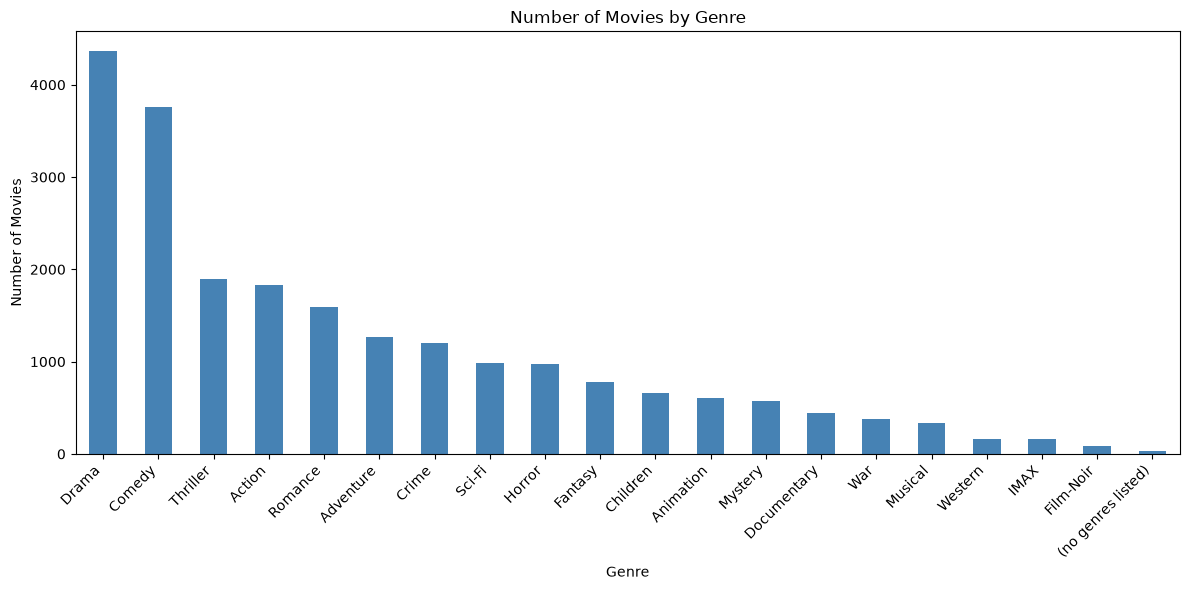

In [7]:
plt.figure(figsize=(12, 6))

genre_counts.plot(kind="bar", color="steelblue")

plt.title("Number of Movies by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [8]:
genre_percentage = genre_counts / len(movies) * 100

print(genre_percentage.round(2))

genres
Drama                 44.76
Comedy                38.55
Thriller              19.44
Action                18.76
Romance               16.38
Adventure             12.96
Crime                 12.31
Sci-Fi                10.06
Horror                10.04
Fantasy                8.00
Children               6.82
Animation              6.27
Mystery                5.88
Documentary            4.52
War                    3.92
Musical                3.43
Western                1.71
IMAX                   1.62
Film-Noir              0.89
(no genres listed)     0.35
Name: count, dtype: float64


In [9]:
no_genre_movies = movies[
    movies["genres"] == "(no genres listed)"
]

print(no_genre_movies.head(10))
print("Number of movies:", len(no_genre_movies))

      movieId                                              title  \
8517   114335                                  La cravate (1957)   
8684   122888                                     Ben-hur (2016)   
8687   122896  Pirates of the Caribbean: Dead Men Tell No Tal...   
8782   129250                                  Superfast! (2015)   
8836   132084                                Let It Be Me (1995)   
8902   134861               Trevor Noah: African American (2013)   
9033   141131                                   Guardians (2016)   
9053   141866                                  Green Room (2015)   
9070   142456                     The Brand New Testament (2015)   
9091   143410                                         Hyena Road   

                  genres  
8517  (no genres listed)  
8684  (no genres listed)  
8687  (no genres listed)  
8782  (no genres listed)  
8836  (no genres listed)  
8902  (no genres listed)  
9033  (no genres listed)  
9053  (no genres listed)  
9070  (n

In [10]:
available_genres = [
    genre for genre in unique_genres
    if genre not in ["(no genres listed)", "IMAX"]
]

available_genres = sorted(available_genres)

print(available_genres)
print("Number of available genres:", len(available_genres))

['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
Number of available genres: 18


In [11]:
print("=== Rating Statistics ===")
print(ratings["rating"].describe())

=== Rating Statistics ===
count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64


In [12]:
rating_counts = ratings["rating"].value_counts()

rating_counts = rating_counts.sort_index()

print("=== Rating Counts ===")
print(rating_counts)

=== Rating Counts ===
rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


In [13]:
rating_percentage = rating_counts / len(ratings) * 100

print("=== Rating Percentage ===")
print(rating_percentage.round(2))

=== Rating Percentage ===
rating
0.5     1.36
1.0     2.79
1.5     1.78
2.0     7.49
2.5     5.50
3.0    19.88
3.5    13.03
4.0    26.60
4.5     8.48
5.0    13.10
Name: count, dtype: float64


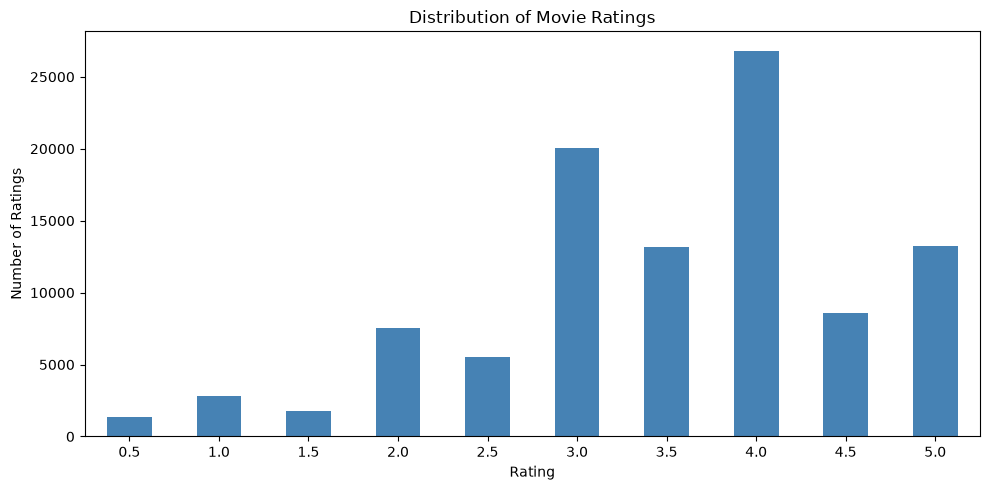

In [14]:
plt.figure(figsize=(10, 5))

rating_counts.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [15]:
mean_rating = ratings["rating"].mean()
median_rating = ratings["rating"].median()

print("Mean rating:", round(mean_rating, 2))
print("Median rating:", median_rating)

Mean rating: 3.5
Median rating: 3.5


In [16]:
user_rating_counts = ratings.groupby("userId")["rating"].count()

print("=== User Rating Counts ===")
print(user_rating_counts.head(10))

=== User Rating Counts ===
userId
1     232
2      29
3      39
4     216
5      44
6     314
7     152
8      47
9      46
10    140
Name: rating, dtype: int64


In [17]:
print("=== User Rating Count Statistics ===")
print(user_rating_counts.describe())

=== User Rating Count Statistics ===
count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
Name: rating, dtype: float64


In [18]:
print("=== Top 10 Most Active Users ===")

print(
    user_rating_counts
    .sort_values(ascending=False)
    .head(10)
)

=== Top 10 Most Active Users ===
userId
414    2698
599    2478
474    2108
448    1864
274    1346
610    1302
68     1260
380    1218
606    1115
288    1055
Name: rating, dtype: int64


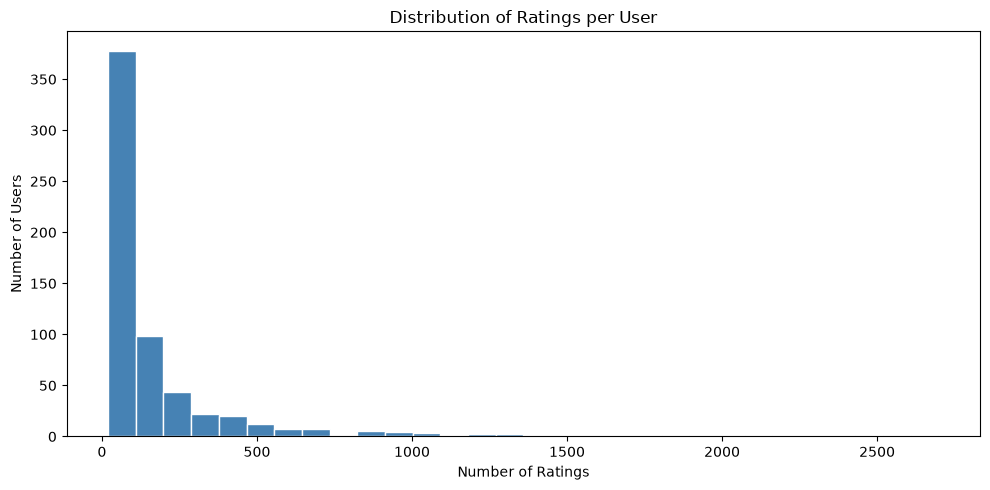

In [19]:
plt.figure(figsize=(10, 5))

plt.hist(
    user_rating_counts,
    bins=30,
    color="steelblue",
    edgecolor="white"
)

plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()

In [20]:
user_mean_ratings = ratings.groupby("userId")["rating"].mean()

print("=== User Mean Ratings ===")
print(user_mean_ratings.head(10))

print("\n=== User Mean Rating Statistics ===")
print(user_mean_ratings.describe())

=== User Mean Ratings ===
userId
1     4.366379
2     3.948276
3     2.435897
4     3.555556
5     3.636364
6     3.493631
7     3.230263
8     3.574468
9     3.260870
10    3.278571
Name: rating, dtype: float64

=== User Mean Rating Statistics ===
count    610.000000
mean       3.657222
std        0.480635
min        1.275000
25%        3.360000
50%        3.694385
75%        3.997500
max        5.000000
Name: rating, dtype: float64


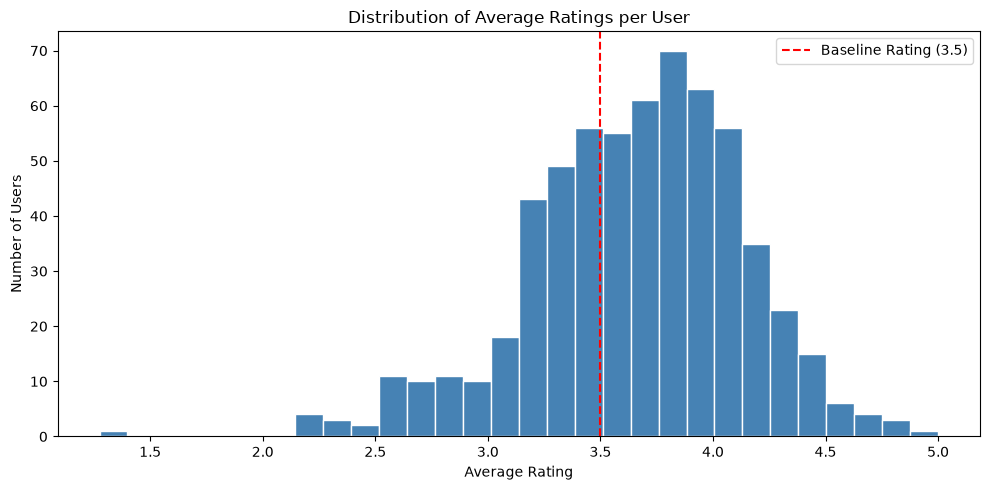

In [21]:
plt.figure(figsize=(10, 5))

plt.hist(
    user_mean_ratings,
    bins=30,
    color="steelblue",
    edgecolor="white"
)

plt.axvline(
    x=3.5,
    color="red",
    linestyle="--",
    label="Baseline Rating (3.5)"
)

plt.title("Distribution of Average Ratings per User")
plt.xlabel("Average Rating")
plt.ylabel("Number of Users")
plt.legend()

plt.tight_layout()
plt.show()

In [22]:
user_stats = ratings.groupby("userId")["rating"].agg(
    ["count", "mean", "std"]
)

print("=== User Statistics ===")
print(user_stats.head(10))

=== User Statistics ===
        count      mean       std
userId                           
1         232  4.366379  0.800048
2          29  3.948276  0.805615
3          39  2.435897  2.090642
4         216  3.555556  1.314204
5          44  3.636364  0.990441
6         314  3.493631  0.850648
7         152  3.230263  1.329594
8          47  3.574468  0.972328
9          46  3.260870  1.272526
10        140  3.278571  1.175700


In [23]:
movie_rating_counts = ratings.groupby("movieId")["rating"].count()

print("=== Movie Rating Counts ===")
print(movie_rating_counts.head(10))

print("\n=== Movie Rating Count Statistics ===")
print(movie_rating_counts.describe())

=== Movie Rating Counts ===
movieId
1     215
2     110
3      52
4       7
5      49
6     102
7      54
8       8
9      16
10    132
Name: rating, dtype: int64

=== Movie Rating Count Statistics ===
count    9724.000000
mean       10.369807
std        22.401005
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       329.000000
Name: rating, dtype: float64


In [24]:
movie_stats = ratings.groupby("movieId")["rating"].agg(
    ["count", "mean", "std"]
)

print("=== Movie Rating Statistics ===")
print(movie_stats.head(10))

=== Movie Rating Statistics ===
         count      mean       std
movieId                           
1          215  3.920930  0.834859
2          110  3.431818  0.881713
3           52  3.259615  1.054823
4            7  2.357143  0.852168
5           49  3.071429  0.907148
6          102  3.946078  0.817224
7           54  3.185185  0.977561
8            8  2.875000  1.125992
9           16  3.125000  0.974679
10         132  3.496212  0.859381


In [25]:
movie_stats = movie_stats.rename(
    columns={
        "count": "rating_count",
        "mean": "rating_mean",
        "std": "rating_std"
    }
)

print(movie_stats.head(10))

         rating_count  rating_mean  rating_std
movieId                                       
1                 215     3.920930    0.834859
2                 110     3.431818    0.881713
3                  52     3.259615    1.054823
4                   7     2.357143    0.852168
5                  49     3.071429    0.907148
6                 102     3.946078    0.817224
7                  54     3.185185    0.977561
8                   8     2.875000    1.125992
9                  16     3.125000    0.974679
10                132     3.496212    0.859381


In [26]:
movie_stats = movie_stats.reset_index()

movies_with_stats = movies.merge(
    movie_stats,
    on="movieId",
    how="left",
    validate="one_to_one"
)

print("=== Movies with Rating Statistics ===")
print(movies_with_stats.head(10))

=== Movies with Rating Statistics ===
   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   
5        6                         Heat (1995)   
6        7                      Sabrina (1995)   
7        8                 Tom and Huck (1995)   
8        9                 Sudden Death (1995)   
9       10                    GoldenEye (1995)   

                                        genres  rating_count  rating_mean  \
0  Adventure|Animation|Children|Comedy|Fantasy         215.0     3.920930   
1                   Adventure|Children|Fantasy         110.0     3.431818   
2                               Comedy|Romance          52.0     3.259615   
3                         Comedy|Drama|Romance           7.0     2.357143   
4                         

In [27]:
unrated_movies = movies_with_stats[
    movies_with_stats["rating_count"].isnull()
]

print("=== Movies without Ratings ===")
print(unrated_movies[["movieId", "title"]])

print("\nNumber of unrated movies:", len(unrated_movies))

unknown_movie_ids = ratings.loc[
    ~ratings["movieId"].isin(movies["movieId"]),
    "movieId"
].nunique()

print("Unknown movie IDs in ratings:", unknown_movie_ids)

=== Movies without Ratings ===
      movieId                                         title
816      1076                         Innocents, The (1961)
2211     2939                                Niagara (1953)
2499     3338                        For All Mankind (1989)
2587     3456  Color of Paradise, The (Rang-e khoda) (1999)
3118     4194                I Know Where I'm Going! (1945)
4037     5721                            Chosen, The (1981)
4506     6668   Road Home, The (Wo de fu qin mu qin) (1999)
4598     6849                                Scrooge (1970)
4704     7020                                  Proof (1991)
5020     7792                     Parallax View, The (1974)
5293     8765                      This Gun for Hire (1942)
5421    25855                  Roaring Twenties, The (1939)
5452    26085                   Mutiny on the Bounty (1962)
5749    30892            In the Realms of the Unreal (2004)
5824    32160                      Twentieth Century (1934)
5837    3

In [28]:
most_rated_movies = movies_with_stats.sort_values(
    by="rating_count",
    ascending=False
)

print("=== Top 10 Most Rated Movies ===")

print(
    most_rated_movies[
        ["title", "rating_count", "rating_mean"]
    ].head(10)
)

=== Top 10 Most Rated Movies ===
                                          title  rating_count  rating_mean
314                         Forrest Gump (1994)         329.0     4.164134
277            Shawshank Redemption, The (1994)         317.0     4.429022
257                         Pulp Fiction (1994)         307.0     4.197068
510            Silence of the Lambs, The (1991)         279.0     4.161290
1939                         Matrix, The (1999)         278.0     4.192446
224   Star Wars: Episode IV - A New Hope (1977)         251.0     4.231076
418                        Jurassic Park (1993)         238.0     3.750000
97                            Braveheart (1995)         237.0     4.031646
507           Terminator 2: Judgment Day (1991)         224.0     3.970982
461                     Schindler's List (1993)         220.0     4.225000


In [29]:
highest_rated_movies = movies_with_stats.sort_values(
    by=["rating_mean", "rating_count"],
    ascending=[False, False]
)

print("=== Top 10 Highest Rated Movies ===")

print(
    highest_rated_movies[
        ["title", "rating_count", "rating_mean"]
    ].head(10)
)

=== Top 10 Highest Rated Movies ===
                                                  title  rating_count  \
48                                      Lamerica (1994)           2.0   
87                 Heidi Fleiss: Hollywood Madam (1995)           2.0   
870                                 Lesson Faust (1994)           2.0   
2597  Jonah Who Will Be 25 in the Year 2000 (Jonas q...           2.0   
4390                                Belle époque (1992)           2.0   
4590                 Come and See (Idi i smotri) (1985)           2.0   
7364                              Enter the Void (2009)           2.0   
121                    Awfully Big Adventure, An (1995)           1.0   
405                              Live Nude Girls (1995)           1.0   
432   In the Realm of the Senses (Ai no corrida) (1976)           1.0   

      rating_mean  
48            5.0  
87            5.0  
870           5.0  
2597          5.0  
4390          5.0  
4590          5.0  
7364          5.0  


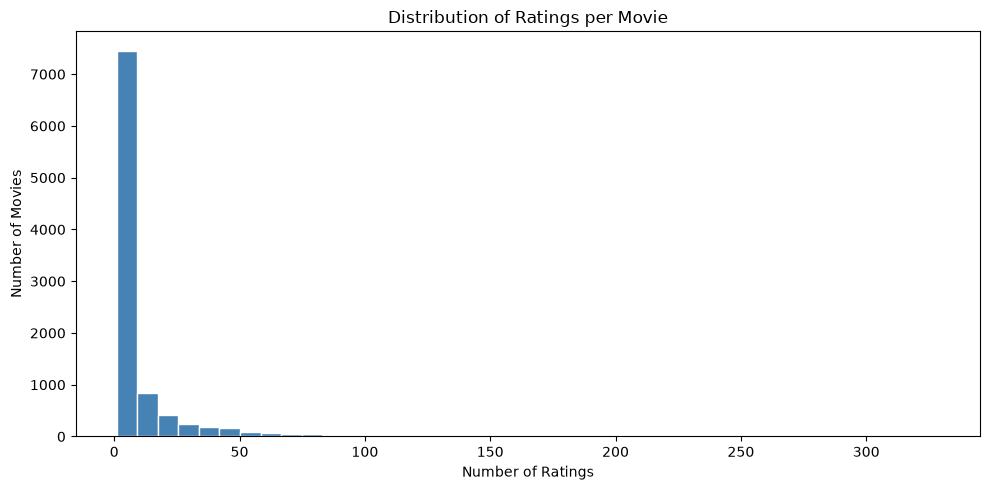

In [30]:
plt.figure(figsize=(10, 5))

plt.hist(
    movie_rating_counts,
    bins=40,
    color="steelblue",
    edgecolor="white"
)

plt.title("Distribution of Ratings per Movie")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

In [31]:
print("=== Movie Rating Count Thresholds ===")

for threshold in [1, 5, 10, 20, 50, 100]:

    count = (movie_rating_counts >= threshold).sum()
    percentage = count / len(movies) * 100

    print(
        f"At least {threshold:3d} ratings: "
        f"{count:5d} movies ({percentage:.2f}%)"
    )

=== Movie Rating Count Thresholds ===
At least   1 ratings:  9724 movies (99.82%)
At least   5 ratings:  3650 movies (37.47%)
At least  10 ratings:  2269 movies (23.29%)
At least  20 ratings:  1297 movies (13.31%)
At least  50 ratings:   450 movies (4.62%)
At least 100 ratings:   138 movies (1.42%)


In [32]:
n_users = ratings["userId"].nunique()
n_movies = movies["movieId"].nunique()

total_possible_ratings = n_users * n_movies
actual_ratings = len(ratings)

density = actual_ratings / total_possible_ratings
sparsity = 1 - density

print("=== Data Sparsity ===")
print("Number of users:", n_users)
print("Number of movies:", n_movies)
print("Total possible ratings:", total_possible_ratings)
print("Actual ratings:", actual_ratings)
print(f"Density: {density:.4%}")
print(f"Sparsity: {sparsity:.4%}")

=== Data Sparsity ===
Number of users: 610
Number of movies: 9742
Total possible ratings: 5942620
Actual ratings: 100836
Density: 1.6968%
Sparsity: 98.3032%


In [33]:
user_item_matrix = ratings.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

print("=== User-Item Matrix ===")
print(user_item_matrix.iloc[:10, :10])

print("\nMatrix shape:", user_item_matrix.shape)

=== User-Item Matrix ===
movieId   1    2    3    4    5    6    7    8   9    10
userId                                                  
1        4.0  NaN  4.0  NaN  NaN  4.0  NaN  NaN NaN  NaN
2        NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN NaN  NaN
3        NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN NaN  NaN
4        NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN NaN  NaN
5        4.0  NaN  NaN  NaN  NaN  NaN  NaN  NaN NaN  NaN
6        NaN  4.0  5.0  3.0  5.0  4.0  4.0  3.0 NaN  3.0
7        4.5  NaN  NaN  NaN  NaN  NaN  NaN  NaN NaN  NaN
8        NaN  4.0  NaN  NaN  NaN  NaN  NaN  NaN NaN  2.0
9        NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN NaN  NaN
10       NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN NaN  NaN

Matrix shape: (610, 9724)


In [34]:
user_item_matrix = user_item_matrix.reindex(
    columns=movies["movieId"]
)

print("=== Full User-Item Matrix ===")
print("Matrix shape:", user_item_matrix.shape)

=== Full User-Item Matrix ===
Matrix shape: (610, 9742)


In [35]:
total_cells = user_item_matrix.size

observed_cells = user_item_matrix.notna().sum().sum()

missing_cells = user_item_matrix.isna().sum().sum()

matrix_density = observed_cells / total_cells
matrix_sparsity = missing_cells / total_cells

print("=== Matrix Sparsity ===")
print("Total cells:", total_cells)
print("Observed cells:", observed_cells)
print("Missing cells:", missing_cells)

print(f"Matrix density: {matrix_density:.4%}")
print(f"Matrix sparsity: {matrix_sparsity:.4%}")

=== Matrix Sparsity ===
Total cells: 5942620
Observed cells: 100836
Missing cells: 5841784
Matrix density: 1.6968%
Matrix sparsity: 98.3032%


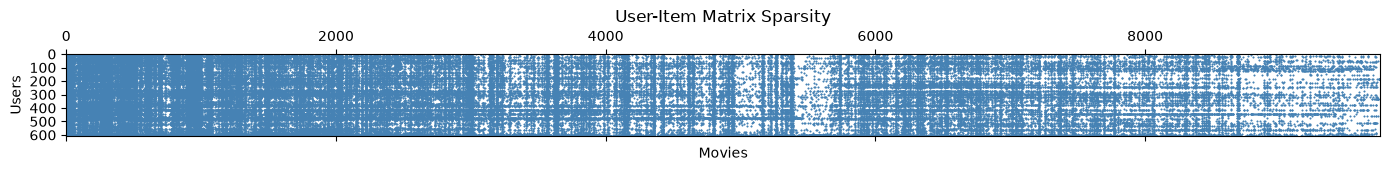

In [36]:
plt.figure(figsize=(14, 6))

plt.spy(
    user_item_matrix.notna().to_numpy(),
    markersize=0.5,
    color="steelblue"
)

plt.title("User-Item Matrix Sparsity")
plt.xlabel("Movies")
plt.ylabel("Users")

plt.tight_layout()
plt.show()

In [37]:
ratings_with_movies = ratings.merge(
    movies,
    on="movieId",
    how="left",
    validate="many_to_one"
)

print("=== Ratings with Movie Information ===")
print(ratings_with_movies.head(10))

print("\nShape:", ratings_with_movies.shape)

=== Ratings with Movie Information ===
   userId  movieId  rating  timestamp                        title  \
0       1        1     4.0  964982703             Toy Story (1995)   
1       1        3     4.0  964981247      Grumpier Old Men (1995)   
2       1        6     4.0  964982224                  Heat (1995)   
3       1       47     5.0  964983815  Seven (a.k.a. Se7en) (1995)   
4       1       50     5.0  964982931   Usual Suspects, The (1995)   
5       1       70     3.0  964982400   From Dusk Till Dawn (1996)   
6       1      101     5.0  964980868         Bottle Rocket (1996)   
7       1      110     4.0  964982176            Braveheart (1995)   
8       1      151     5.0  964984041               Rob Roy (1995)   
9       1      157     5.0  964984100        Canadian Bacon (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                               Comedy|Romance  
2                        Action|Crime|Thril

In [38]:
target_user = 1

user_movies = ratings_with_movies[
    ratings_with_movies["userId"] == target_user
].copy()

print("=== User Movie History ===")

print(
    user_movies[
        ["movieId", "title", "genres", "rating"]
    ].head(10)
)

print("\nNumber of rated movies:", len(user_movies))

print("Average rating:", user_movies["rating"].mean())

=== User Movie History ===
   movieId                        title  \
0        1             Toy Story (1995)   
1        3      Grumpier Old Men (1995)   
2        6                  Heat (1995)   
3       47  Seven (a.k.a. Se7en) (1995)   
4       50   Usual Suspects, The (1995)   
5       70   From Dusk Till Dawn (1996)   
6      101         Bottle Rocket (1996)   
7      110            Braveheart (1995)   
8      151               Rob Roy (1995)   
9      157        Canadian Bacon (1995)   

                                        genres  rating  
0  Adventure|Animation|Children|Comedy|Fantasy     4.0  
1                               Comedy|Romance     4.0  
2                        Action|Crime|Thriller     4.0  
3                             Mystery|Thriller     5.0  
4                       Crime|Mystery|Thriller     5.0  
5                Action|Comedy|Horror|Thriller     3.0  
6               Adventure|Comedy|Crime|Romance     5.0  
7                             Action|Drama|

In [39]:
user_movies["genres"] = user_movies["genres"].str.split("|")

user_genres = user_movies.explode("genres")

print("=== User Ratings by Genre ===")

print(
    user_genres[
        ["title", "genres", "rating"]
    ].head(15)
)

=== User Ratings by Genre ===
                         title     genres  rating
0             Toy Story (1995)  Adventure     4.0
0             Toy Story (1995)  Animation     4.0
0             Toy Story (1995)   Children     4.0
0             Toy Story (1995)     Comedy     4.0
0             Toy Story (1995)    Fantasy     4.0
1      Grumpier Old Men (1995)     Comedy     4.0
1      Grumpier Old Men (1995)    Romance     4.0
2                  Heat (1995)     Action     4.0
2                  Heat (1995)      Crime     4.0
2                  Heat (1995)   Thriller     4.0
3  Seven (a.k.a. Se7en) (1995)    Mystery     5.0
3  Seven (a.k.a. Se7en) (1995)   Thriller     5.0
4   Usual Suspects, The (1995)      Crime     5.0
4   Usual Suspects, The (1995)    Mystery     5.0
4   Usual Suspects, The (1995)   Thriller     5.0


In [40]:
user_genres = user_genres[
    ~user_genres["genres"].isin(
        ["(no genres listed)", "IMAX"]
    )
].copy()

print(user_genres.head(10))

   userId  movieId  rating  timestamp                    title     genres
0       1        1     4.0  964982703         Toy Story (1995)  Adventure
0       1        1     4.0  964982703         Toy Story (1995)  Animation
0       1        1     4.0  964982703         Toy Story (1995)   Children
0       1        1     4.0  964982703         Toy Story (1995)     Comedy
0       1        1     4.0  964982703         Toy Story (1995)    Fantasy
1       1        3     4.0  964981247  Grumpier Old Men (1995)     Comedy
1       1        3     4.0  964981247  Grumpier Old Men (1995)    Romance
2       1        6     4.0  964982224              Heat (1995)     Action
2       1        6     4.0  964982224              Heat (1995)      Crime
2       1        6     4.0  964982224              Heat (1995)   Thriller


In [41]:
user_genre_stats = user_genres.groupby("genres")["rating"].agg(
    ["count", "mean", "std"]
)

user_genre_stats = user_genre_stats.rename(
    columns={
        "count": "rating_count",
        "mean": "rating_mean",
        "std": "rating_std"
    }
)

print("=== User Genre Statistics ===")
print(user_genre_stats.round(3))

=== User Genre Statistics ===
           rating_count  rating_mean  rating_std
genres                                          
Action               90        4.322       0.762
Adventure            85        4.388       0.742
Animation            29        4.690       0.604
Children             42        4.548       0.705
Comedy               83        4.277       0.786
Crime                45        4.356       0.830
Drama                68        4.529       0.722
Fantasy              47        4.298       0.805
Film-Noir             1        5.000         NaN
Horror               17        3.471       1.068
Musical              22        4.682       0.646
Mystery              18        4.167       1.249
Romance              26        4.308       0.618
Sci-Fi               40        4.225       0.768
Thriller             55        4.145       0.989
War                  22        4.500       0.673
Western               7        4.286       0.756


In [42]:
print("=== Most Frequently Rated Genres ===")

print(
    user_genre_stats.sort_values(
        by="rating_count",
        ascending=False
    )
)

=== Most Frequently Rated Genres ===
           rating_count  rating_mean  rating_std
genres                                          
Action               90     4.322222    0.761840
Adventure            85     4.388235    0.741525
Comedy               83     4.277108    0.785746
Drama                68     4.529412    0.722157
Thriller             55     4.145455    0.989167
Fantasy              47     4.297872    0.805279
Crime                45     4.355556    0.829993
Children             42     4.547619    0.705462
Sci-Fi               40     4.225000    0.767530
Animation            29     4.689655    0.603765
Romance              26     4.307692    0.617688
War                  22     4.500000    0.672593
Musical              22     4.681818    0.646335
Mystery              18     4.166667    1.248529
Horror               17     3.470588    1.067570
Western               7     4.285714    0.755929
Film-Noir             1     5.000000         NaN


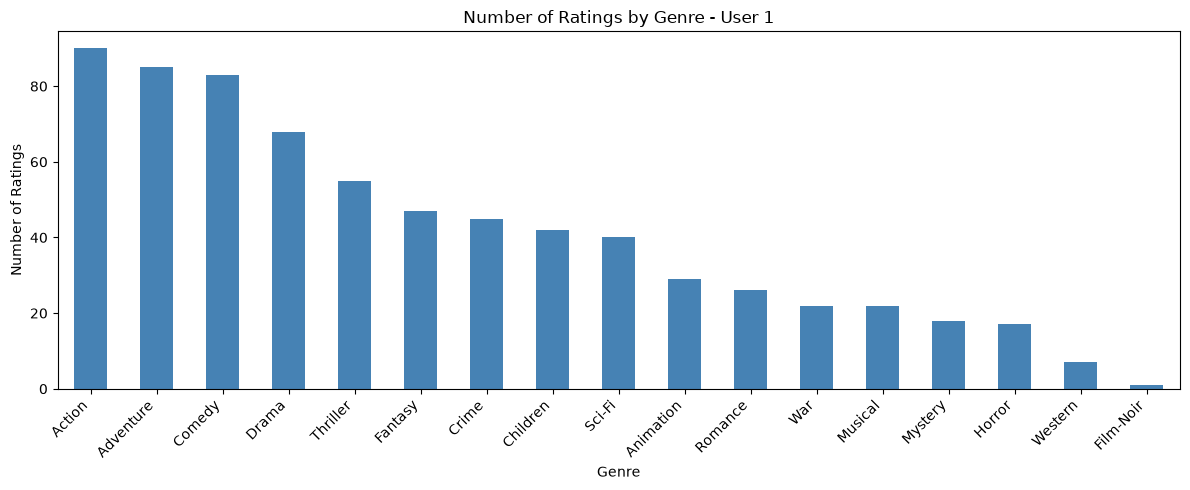

In [43]:
plt.figure(figsize=(12, 5))

user_genre_stats["rating_count"].sort_values(
    ascending=False
).plot(
    kind="bar",
    color="steelblue"
)

plt.title(f"Number of Ratings by Genre - User {target_user}")
plt.xlabel("Genre")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [44]:
print("=== Highest Rated Genres ===")

print(
    user_genre_stats.sort_values(
        by="rating_mean",
        ascending=False
    )
)

=== Highest Rated Genres ===
           rating_count  rating_mean  rating_std
genres                                          
Film-Noir             1     5.000000         NaN
Animation            29     4.689655    0.603765
Musical              22     4.681818    0.646335
Children             42     4.547619    0.705462
Drama                68     4.529412    0.722157
War                  22     4.500000    0.672593
Adventure            85     4.388235    0.741525
Crime                45     4.355556    0.829993
Action               90     4.322222    0.761840
Romance              26     4.307692    0.617688
Fantasy              47     4.297872    0.805279
Western               7     4.285714    0.755929
Comedy               83     4.277108    0.785746
Sci-Fi               40     4.225000    0.767530
Mystery              18     4.166667    1.248529
Thriller             55     4.145455    0.989167
Horror               17     3.470588    1.067570


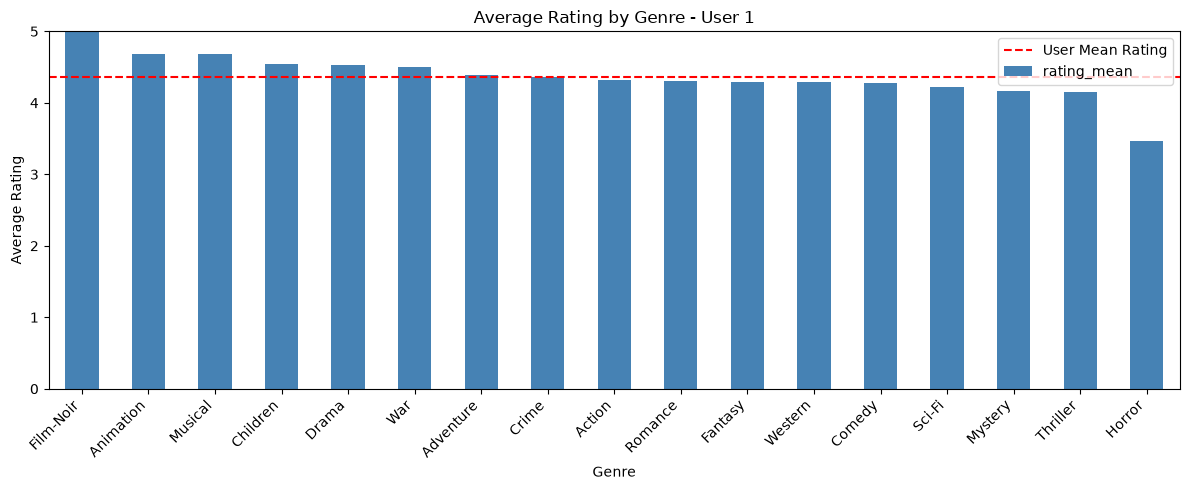

In [45]:
plt.figure(figsize=(12, 5))

user_genre_stats["rating_mean"].sort_values(
    ascending=False
).plot(
    kind="bar",
    color="steelblue"
)

plt.axhline(
    y=user_movies["rating"].mean(),
    color="red",
    linestyle="--",
    label="User Mean Rating"
)

plt.title(f"Average Rating by Genre - User {target_user}")
plt.xlabel("Genre")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.xticks(rotation=45, ha="right")
plt.legend()

plt.tight_layout()
plt.show()

In [46]:
baseline_rating = 3.5

user_genres["preference_weight"] = (
    user_genres["rating"] - baseline_rating
)

print(
    user_genres[
        ["title", "genres", "rating", "preference_weight"]
    ].head(15)
)

                         title     genres  rating  preference_weight
0             Toy Story (1995)  Adventure     4.0                0.5
0             Toy Story (1995)  Animation     4.0                0.5
0             Toy Story (1995)   Children     4.0                0.5
0             Toy Story (1995)     Comedy     4.0                0.5
0             Toy Story (1995)    Fantasy     4.0                0.5
1      Grumpier Old Men (1995)     Comedy     4.0                0.5
1      Grumpier Old Men (1995)    Romance     4.0                0.5
2                  Heat (1995)     Action     4.0                0.5
2                  Heat (1995)      Crime     4.0                0.5
2                  Heat (1995)   Thriller     4.0                0.5
3  Seven (a.k.a. Se7en) (1995)    Mystery     5.0                1.5
3  Seven (a.k.a. Se7en) (1995)   Thriller     5.0                1.5
4   Usual Suspects, The (1995)      Crime     5.0                1.5
4   Usual Suspects, The (1995)    

In [47]:
genre_preference = user_genres.groupby(
    "genres"
)["preference_weight"].agg(
    ["count", "sum", "mean"]
)

genre_preference = genre_preference.rename(
    columns={
        "count": "rating_count",
        "sum": "total_preference",
        "mean": "average_preference"
    }
)

print("=== Genre Preference Scores ===")

print(
    genre_preference.sort_values(
        by="total_preference",
        ascending=False
    ).round(3)
)

=== Genre Preference Scores ===
           rating_count  total_preference  average_preference
genres                                                       
Adventure            85              75.5               0.888
Action               90              74.0               0.822
Drama                68              70.0               1.029
Comedy               83              64.5               0.777
Children             42              44.0               1.048
Crime                45              38.5               0.856
Fantasy              47              37.5               0.798
Thriller             55              35.5               0.645
Animation            29              34.5               1.190
Sci-Fi               40              29.0               0.725
Musical              22              26.0               1.182
War                  22              22.0               1.000
Romance              26              21.0               0.808
Mystery              18              1

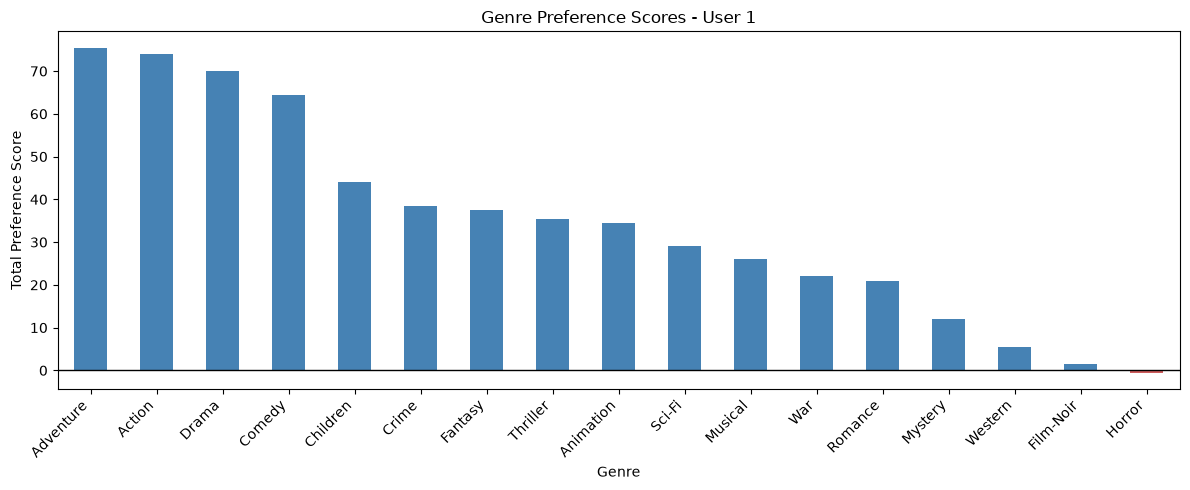

In [48]:
preference_sorted = genre_preference[
    "total_preference"
].sort_values(ascending=False)

colors = [
    "steelblue" if score >= 0 else "indianred"
    for score in preference_sorted
]

plt.figure(figsize=(12, 5))

preference_sorted.plot(
    kind="bar",
    color=colors
)

plt.axhline(y=0, color="black", linewidth=1)

plt.title(f"Genre Preference Scores - User {target_user}")
plt.xlabel("Genre")
plt.ylabel("Total Preference Score")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()